# Lab 13 — Data and adaptation

**Book sections:** [9.1](../../book/docs/chapters/09-training/stages.md)–[9.5](../../book/docs/chapters/09-training/evaluation.md).

**Goal.** Do the data and adaptation work that sits between a pretrained VLA and a robot:

1. **record** demonstrations with timestamps, task strings and outcome labels;
2. **store** them in the LeRobot dataset layout (Parquet tables + MP4 videos + metadata), read them back by hand,
   and check what video compression does to a policy;
3. **adapt** the policy to a new task — objects of a kind it has never been asked to reach (cones) — by full
   fine-tuning and by LoRA at several ranks, with and without co-training, measuring success, trainable
   parameters, memory and *forgetting* of the original task;
4. **report** every number with a confidence interval and compare methods with paired episodes.

**Runtime:** ≈30 min with a GPU. **Downloads:** none. **Disk:** ≈100 MB in `data/lerobot/`. **GPU:** ≈1.5 GB.
**Seed:** 0. **Reads** `data/checkpoints/tiny_clip.pt` from Lab 07.

In [1]:
import json
import math
import shutil
import time
from pathlib import Path

import av
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from vlacourse.clip import TinyCLIP
from vlacourse.data import scenes
from vlacourse.depot_env import INSTR_VOCAB, DepotNav, collect, encode_instruction, evaluate, pad_instructions
from vlacourse.lora import add_lora
from vlacourse.seed import device, set_seed
from vlacourse.vision import to_tensor
from vlacourse.vla import TinyVLA

set_seed(0)
dev = device()
pd.set_option("display.width", 150)
CK = Path("../../data/checkpoints")
ROOT = Path("../../data/lerobot/depot_nav")
FPS, H_A = 10, 8
BASE_KINDS = ("toolbox", "crate", "barrel")          # the original task never involves cones
print("device:", dev)

device: cuda


## 1. Recording demonstrations
A recorder stores, per episode, every observation, the **commanded** action, the task string, timestamps and
the outcome. 95% of episodes come from the scripted expert; 5% from a sloppy "operator" (large action noise),
about half of whose attempts fail — real datasets contain failed or poor demonstrations, and the outcome label is
how you find the failed ones. (The sloppy *successes* stay in: outcome labels do not measure quality.)

In [2]:
def record(n_episodes, seed, env, tasks_per_scene=3, sloppy=0.05):
    rng = np.random.default_rng(seed)
    episodes = []
    for ep in range(n_episodes):
        obs = env.reset(seed) if ep == 0 else env.reset(keep_scene=ep % tasks_per_scene != 0)
        noise = 2.5 if rng.random() < sloppy else 0.0
        frames, states, actions, done, ok = [], [], [], False, False
        while not done:
            a = env.expert_action(noise)
            frames.append(obs["image"]); states.append(obs["state"]); actions.append(a)
            obs, done, ok = env.step(a)
        episodes.append(dict(images=np.array(frames), state=np.array(states, np.float32),
                             action=np.array(actions, np.float32), task=obs["instruction"], success=bool(ok)))
    return episodes


t0 = time.time()
episodes = record(6000, seed=1, env=DepotNav(kinds=BASE_KINDS))
lengths = np.array([len(e["action"]) for e in episodes])
print(f"{len(episodes)} episodes, {lengths.sum()} frames, mean length {lengths.mean():.1f} "
      f"({time.time() - t0:.0f} s); successful: {np.mean([e['success'] for e in episodes]):.3f}")

6000 episodes, 77986 frames, mean length 13.0 (150 s); successful: 0.978


## 2. The LeRobot dataset layout
We write the layout used by LeRobot datasets (version 2.1 of the format): one Parquet table and one MP4 per
episode, grouped in chunks of 1000 episodes, plus metadata. (Version 3 groups many episodes per file; the
content is the same.)

In [3]:
def write_video(path, frames, fps=FPS, crf=23):
    path.parent.mkdir(parents=True, exist_ok=True)
    with av.open(str(path), "w") as c:
        s = c.add_stream("libx264", rate=fps)
        s.width, s.height, s.pix_fmt = frames.shape[2], frames.shape[1], "yuv420p"
        s.options = {"crf": str(crf), "g": "2"}             # a key frame every 2 frames: fast random access
        for f in frames:
            for p in s.encode(av.VideoFrame.from_ndarray(f, format="rgb24")):
                c.mux(p)
        for p in s.encode():
            c.mux(p)


def stats_of(x):
    x = np.asarray(x, np.float64)
    return {"mean": x.mean(0).tolist(), "std": x.std(0).tolist(), "min": x.min(0).tolist(), "max": x.max(0).tolist(),
            "q01": np.quantile(x, 0.01, 0).tolist(), "q99": np.quantile(x, 0.99, 0).tolist()}


def write_lerobot(root, episodes, fps=FPS):
    shutil.rmtree(root, ignore_errors=True)
    (root / "meta").mkdir(parents=True)
    tasks = {t: i for i, t in enumerate(sorted({e["task"] for e in episodes}))}
    index = 0
    with open(root / "meta" / "episodes.jsonl", "w") as fe:
        for k, e in enumerate(episodes):
            n = len(e["action"])
            chunk = f"chunk-{k // 1000:03d}"
            (root / "data" / chunk).mkdir(parents=True, exist_ok=True)
            pd.DataFrame({
                "observation.state": list(e["state"]), "action": list(e["action"]),
                "timestamp": np.arange(n, dtype=np.float32) / fps, "frame_index": np.arange(n),
                "episode_index": k, "index": np.arange(index, index + n), "task_index": tasks[e["task"]],
                "next.done": np.arange(n) == n - 1,
            }).to_parquet(root / "data" / chunk / f"episode_{k:06d}.parquet")
            write_video(root / "videos" / chunk / "observation.images.top" / f"episode_{k:06d}.mp4", e["images"], fps)
            fe.write(json.dumps({"episode_index": k, "tasks": [e["task"]], "length": n, "success": e["success"]}) + "\n")
            index += n
    with open(root / "meta" / "tasks.jsonl", "w") as ft:
        for t, i in tasks.items():
            ft.write(json.dumps({"task_index": i, "task": t}) + "\n")
    res = episodes[0]["images"].shape[1]
    info = {"codebase_version": "v2.1", "robot_type": "depot_point_robot", "fps": fps,
            "total_episodes": len(episodes), "total_frames": index, "total_tasks": len(tasks), "chunks_size": 1000,
            "data_path": "data/chunk-{episode_chunk:03d}/episode_{episode_index:06d}.parquet",
            "video_path": "videos/chunk-{episode_chunk:03d}/{video_key}/episode_{episode_index:06d}.mp4",
            "features": {
                "observation.images.top": {"dtype": "video", "shape": [res, res, 3], "names": ["height", "width", "channel"],
                                           "info": {"video.codec": "h264", "video.pix_fmt": "yuv420p", "video.fps": fps}},
                "observation.state": {"dtype": "float32", "shape": [2], "names": ["x", "y"]},
                "action": {"dtype": "float32", "shape": [2], "names": ["vx", "vy"]},
                "timestamp": {"dtype": "float32", "shape": [1]}, "frame_index": {"dtype": "int64", "shape": [1]},
                "episode_index": {"dtype": "int64", "shape": [1]}, "index": {"dtype": "int64", "shape": [1]},
                "task_index": {"dtype": "int64", "shape": [1]}, "next.done": {"dtype": "bool", "shape": [1]}}}
    (root / "meta" / "info.json").write_text(json.dumps(info, indent=2))
    sample = np.concatenate([e["images"][::5] for e in episodes[:500]]).reshape(-1, 3) / 255
    stats = {"observation.state": stats_of(np.concatenate([e["state"] for e in episodes])),
             "action": stats_of(np.concatenate([e["action"] for e in episodes])),
             "observation.images.top": {"mean": sample.mean(0).tolist(), "std": sample.std(0).tolist()}}
    (root / "meta" / "stats.json").write_text(json.dumps(stats, indent=2))


t0 = time.time()
write_lerobot(ROOT, episodes)
size = lambda p: sum(f.stat().st_size for f in p.rglob("*") if f.is_file())  # noqa: E731
raw = sum(e["images"].nbytes for e in episodes)
print(f"written in {time.time() - t0:.0f} s: data {size(ROOT / 'data') / 1e6:.1f} MB, videos {size(ROOT / 'videos') / 1e6:.1f} MB "
      f"(raw frames would be {raw / 1e6:.0f} MB), meta {size(ROOT / 'meta') / 1e3:.0f} kB")
for p in sorted(ROOT.rglob("*"))[:4] + sorted((ROOT / "videos").rglob("*.mp4"))[:1] + sorted((ROOT / "meta").glob("*")):
    print("  ", p.relative_to(ROOT))

written in 104 s: data 36.6 MB, videos 61.5 MB (raw frames would be 958 MB), meta 545 kB


   data
   data/chunk-000
   data/chunk-000/episode_000000.parquet
   data/chunk-000/episode_000001.parquet
   videos/chunk-000/observation.images.top/episode_000000.mp4
   meta/episodes.jsonl
   meta/info.json
   meta/stats.json
   meta/tasks.jsonl


### Reading it back by hand
The metadata first: frame rate, feature schema, tasks, outcomes.

In [4]:
info = json.loads((ROOT / "meta" / "info.json").read_text())
print("fps:", info["fps"], "| features:", list(info["features"]))
tasks = pd.read_json(ROOT / "meta" / "tasks.jsonl", lines=True)
eps = pd.read_json(ROOT / "meta" / "episodes.jsonl", lines=True)
print(f"{len(tasks)} distinct task strings, e.g. {tasks.task.tolist()[:3]}")
print(f"failed episodes: {(~eps.success).sum()} of {len(eps)} — filter them out before training")
frames = pd.concat(pd.read_parquet(p) for p in sorted((ROOT / "data").rglob("*.parquet")))
print(frames[frames.episode_index == 0][["index", "frame_index", "timestamp", "observation.state", "action",
                                         "task_index"]].head().to_string())

fps: 10 | features: ['observation.images.top', 'observation.state', 'action', 'timestamp', 'frame_index', 'episode_index', 'index', 'task_index', 'next.done']
19 distinct task strings, e.g. ['go to the barrel', 'go to the blue barrel', 'go to the blue crate']
failed episodes: 132 of 6000 — filter them out before training


   index  frame_index  timestamp        observation.state                    action  task_index
0      0            0        0.0   [0.5902479, 0.7244124]  [0.21475571, -0.9766678]          14
1      1            1        0.1  [0.59883815, 0.6853457]  [0.21475571, -0.9766678]          14
2      2            2        0.2    [0.6074284, 0.646279]   [0.2147557, -0.9766678]          14
3      3            3        0.3  [0.6160186, 0.60721225]  [0.21475571, -0.9766678]          14
4      4            4        0.4   [0.6246088, 0.5681456]  [0.21475571, -0.9766678]          14


Now decode the videos, rebuild the training tensors the way LeRobot's `delta_timestamps` does (the action
*chunk* for frame $t$ is the actions at $t, t+\Delta t, \dots, t+7\Delta t$, zero-padded past the end of the
episode), and drop failed episodes.

In [5]:
def decode(path):
    with av.open(str(path)) as c:
        return np.stack([f.to_ndarray(format="rgb24") for f in c.decode(video=0)])


def load_lerobot(root, only_success=True):
    info = json.loads((root / "meta" / "info.json").read_text())
    tasks = pd.read_json(root / "meta" / "tasks.jsonl", lines=True).set_index("task_index").task
    eps = pd.read_json(root / "meta" / "episodes.jsonl", lines=True)
    out = {k: [] for k in ("image", "state", "chunk", "instruction")}
    for _, e in eps.iterrows():
        if only_success and not e.success:
            continue
        k, chunk = e.episode_index, f"chunk-{e.episode_index // info['chunks_size']:03d}"
        df = pd.read_parquet(root / "data" / chunk / f"episode_{k:06d}.parquet")
        imgs = decode(root / "videos" / chunk / "observation.images.top" / f"episode_{k:06d}.mp4")
        assert len(imgs) == len(df), "video and table must have the same frames"
        act = np.stack(df.action.to_numpy()).astype(np.float32)
        padded = np.concatenate([act, np.zeros((H_A, act.shape[1]), np.float32)])
        ids = encode_instruction(tasks[df.task_index.iloc[0]])
        for t in range(len(df)):
            out["image"].append(imgs[t]); out["state"].append(df["observation.state"].iloc[t])
            out["chunk"].append(padded[t:t + H_A]); out["instruction"].append(ids)
    return {k: (v if k == "instruction" else np.array(v, dtype=np.uint8 if k == "image" else np.float32))
            for k, v in out.items()}


t0 = time.time()
R = load_lerobot(ROOT)
M = {"image": np.concatenate([e["images"] for e in episodes if e["success"]])}
err = np.abs(R["image"].astype(int) - M["image"].astype(int))
print(f"read back {len(R['chunk'])} frames in {time.time() - t0:.0f} s; "
      f"mean |decoded - original| = {err.mean():.1f}/255, 99th percentile {np.percentile(err, 99):.0f}/255")

read back 71386 frames in 96 s; mean |decoded - original| = 7.0/255, 99th percentile 33/255


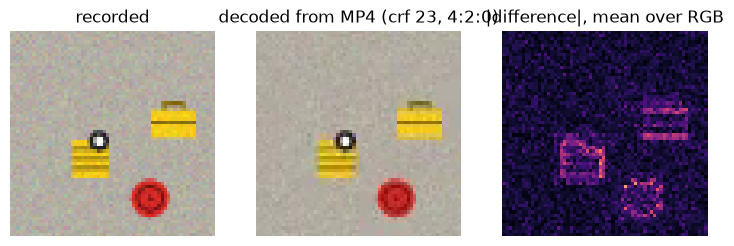

In [6]:
k = 40
fig, axs = plt.subplots(1, 3, figsize=(9, 3.2))
axs[0].imshow(M["image"][k]); axs[0].set_title("recorded")
axs[1].imshow(R["image"][k]); axs[1].set_title("decoded from MP4 (crf 23, 4:2:0)")
axs[2].imshow(err[k].mean(-1), cmap="magma", vmin=0, vmax=60); axs[2].set_title("|difference|, mean over RGB")
for a in axs:
    a.axis("off")
plt.show()

The error concentrates on object edges and colours: H.264 stores colour at half resolution (4:2:0), which on a
64-pixel image smears the small objects' colours. Does it matter for a policy? Train the Lab 11 recipe (regression
head, frozen tiny-CLIP encoder) twice on the same successful episodes — once on the recorded frames, once on the
decoded ones — and evaluate both on the live environment, whose camera images are *not* compressed.

In [7]:
def to_tensors(D):
    return [torch.as_tensor(D["image"]), torch.as_tensor(pad_instructions(D["instruction"], 5)),
            torch.as_tensor(D["state"]), torch.as_tensor(D["chunk"])]


def new_vla():
    clip = TinyCLIP(len(scenes.VOCAB))
    if (CK / "tiny_clip.pt").exists():
        clip.load_state_dict(torch.load(CK / "tiny_clip.pt", map_location="cpu"))
    m = TinyVLA(len(INSTR_VOCAB), head="mse", vision=clip.image_encoder).to(dev)
    for p in m.vision.parameters():
        p.requires_grad = False
    return m


def train(m, data, params, steps, lr, mix_data=None, mix=0.0, seed=0):
    """AdamW + one-cycle on `params`; with mix_data, a fraction `mix` of every batch comes from it (co-training)."""
    set_seed(seed)
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=0.0)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=steps, pct_start=0.05)
    m.train()
    nb = int(128 * mix) if mix_data is not None else 0
    for _ in range(steps):
        parts = []
        for D, n in [(data, 128 - nb), (mix_data, nb)]:
            if n:
                j = torch.randint(0, len(D[0]), (n,))
                parts.append([t[j] for t in D])
        X, I, S, A = [torch.cat(z) for z in zip(*parts)]
        loss = m.loss(to_tensor(X).to(dev), I.to(dev), S.to(dev), A.to(dev))
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(params, 1.0); opt.step(); sched.step()
    return m.eval()


def trainable(m):
    return [p for p in m.parameters() if p.requires_grad]


def policy_of(m):
    def pol(img, ins, st):
        with torch.no_grad():
            return m.act(to_tensor(img).to(dev), torch.as_tensor(ins).to(dev), torch.as_tensor(st).to(dev)).cpu().numpy()
    return pol


def wilson(k, n, z=1.96):
    p = k / n
    c = (p + z * z / (2 * n)) / (1 + z * z / n)
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return c - h, c + h


BASE_ENV = lambda: DepotNav(kinds=BASE_KINDS)          # noqa: E731
NEW_ENV = lambda: DepotNav(target_kinds=("cone",))     # noqa: E731


def score(m, env_factory, n=300, seed=50_000):
    s = evaluate(policy_of(m), n, seed=seed, execute=4, env_factory=env_factory)["success"]
    return s


def fmt(s):
    lo, hi = wilson(s.sum(), len(s))
    return f"{s.mean():.2f} [{max(lo, 0):.2f}, {min(hi, 1):.2f}]"


TRAIN_STEPS = 4000
REC = to_tensors({"image": M["image"], **{k: R[k] for k in ("state", "chunk", "instruction")}})
DEC = to_tensors(R)
models = {}
for name, D in [("recorded frames", REC), ("decoded MP4 frames", DEC)]:
    t0 = time.time()
    m = new_vla()
    models[name] = train(m, D, trainable(m), TRAIN_STEPS, 3e-4)
    print(f"trained on {name:20s}: success on the original task {fmt(score(models[name], BASE_ENV))} "
          f"({time.time() - t0:.0f} s)")

trained on recorded frames     : success on the original task 0.50 [0.45, 0.56] (507 s)


trained on decoded MP4 frames  : success on the original task 0.76 [0.71, 0.80] (474 s)


Compare the two intervals before concluding anything (book 9.5). In the committed run the policy trained on the
*decoded* frames did markedly better (0.76 vs 0.50). A plausible reason is that compression smooths fine detail and
acts like data augmentation — but this is one training seed per condition, and exercise 7 asks you to separate the
effect from training variance. Either way the lesson is about pipelines: the policy trains on decoded video and acts
on raw camera frames, so the codec settings are part of the model's input distribution and belong in the dataset
metadata — which is why LeRobot records them.
From here on the model trained on the dataset as stored (decoded frames) is the **base policy**.

## 3. A new task: cones
The base policy has never been asked to go to a cone: cones never appeared in its demonstrations, and the word
"cone" was never in an instruction (its embedding is still random). The frozen vision encoder, however, saw cones
during Lab 07's contrastive training. Collect a small adaptation set — 300 episodes whose instructions all name
cones — and evaluate the base policy on both tasks.

In [8]:
base = models["decoded MP4 frames"]
torch.save(base.state_dict(), CK / "lab13_base.pt")
NEW = to_tensors(collect(300, seed=3, chunk=H_A, env=NEW_ENV(), tasks_per_scene=3))
print(f"adaptation set: {len(NEW[0])} frames")
base_scores = {"original": score(base, BASE_ENV), "cones": score(base, NEW_ENV)}
print(f"base policy: original task {fmt(base_scores['original'])}, cones {fmt(base_scores['cones'])}")

adaptation set: 3483 frames


base policy: original task 0.76 [0.71, 0.80], cones 0.15 [0.11, 0.19]


### Full fine-tuning vs LoRA
Every method starts from the base policy and takes 1500 steps on the adaptation set. **Full fine-tuning**
updates all parameters outside the frozen vision encoder (lr $10^{-4}$). **LoRA** freezes them too and adds rank-$r$
adapters to every linear layer of the backbone and the action head (lr $10^{-3}$; book 9.4). **Co-training**
keeps half of every batch from the original data (book 9.1).

In [9]:
def adapt(method, r=None, mix=0.0, steps=1500):
    m = new_vla()
    m.load_state_dict(base.state_dict())
    if method == "full":
        params, lr = trainable(m), 1e-4
    else:
        for p in m.parameters():
            p.requires_grad = False
        params = add_lora(m.blocks, r) + add_lora(m.mse_head, r)
        lr = 1e-3
    n_train = sum(p.numel() for p in params)
    t0 = time.time()
    train(m, NEW, params, steps, lr, mix_data=DEC if mix else None, mix=mix)
    return m, n_train, time.time() - t0


runs = [("full fine-tune", "full", None, 0.0), ("full + co-training", "full", None, 0.5)] + \
       [(f"LoRA r={r}", "lora", r, 0.0) for r in (1, 2, 4, 8, 32)] + [("LoRA r=8 + co-training", "lora", 8, 0.5)]
rows = []
for label, method, r, mix in runs:
    m, n_train, dt = adapt(method, r, mix)
    s_old, s_new = score(m, BASE_ENV), score(m, NEW_ENV)
    rows.append(dict(method=label, trainable=n_train, cones=s_new, original=s_old))
    print(f"{label:24s} trainable {n_train:>8,}  cones {fmt(s_new)}  original {fmt(s_old)}  ({dt:.0f} s)")

full fine-tune           trainable 1,163,408  cones 0.68 [0.63, 0.73]  original 0.44 [0.38, 0.49]  (178 s)


full + co-training       trainable 1,163,408  cones 0.61 [0.56, 0.67]  original 0.77 [0.72, 0.82]  (175 s)


LoRA r=1                 trainable   12,944  cones 0.80 [0.75, 0.84]  original 0.43 [0.38, 0.49]  (184 s)


LoRA r=2                 trainable   25,888  cones 0.79 [0.74, 0.83]  original 0.42 [0.37, 0.48]  (201 s)


LoRA r=4                 trainable   51,776  cones 0.74 [0.69, 0.79]  original 0.41 [0.36, 0.47]  (133 s)


LoRA r=8                 trainable  103,552  cones 0.71 [0.65, 0.76]  original 0.38 [0.33, 0.44]  (99 s)


LoRA r=32                trainable  414,208  cones 0.68 [0.63, 0.73]  original 0.38 [0.33, 0.44]  (101 s)


LoRA r=8 + co-training   trainable  103,552  cones 0.65 [0.59, 0.70]  original 0.78 [0.73, 0.82]  (168 s)


### Memory
Training memory beyond the frozen weights is dominated by what is kept *per trainable parameter*: the gradient
and AdamW's two moment estimates (12 bytes in fp32), plus activations. LoRA shrinks the first term by the ratio
of trainable parameters — negligible at this toy scale, decisive for a 7 B model (book 9.4).

In [10]:
total = sum(p.numel() for p in base.parameters())
for row in rows:
    print(f"{row['method']:24s} {row['trainable'] / total:6.1%} of {total:,} parameters trainable -> "
          f"{row['trainable'] * 12 / 1e6:6.2f} MB of gradients + optimizer state")

full fine-tune            51.8% of 2,246,288 parameters trainable ->  13.96 MB of gradients + optimizer state
full + co-training        51.8% of 2,246,288 parameters trainable ->  13.96 MB of gradients + optimizer state
LoRA r=1                   0.6% of 2,246,288 parameters trainable ->   0.16 MB of gradients + optimizer state
LoRA r=2                   1.2% of 2,246,288 parameters trainable ->   0.31 MB of gradients + optimizer state
LoRA r=4                   2.3% of 2,246,288 parameters trainable ->   0.62 MB of gradients + optimizer state
LoRA r=8                   4.6% of 2,246,288 parameters trainable ->   1.24 MB of gradients + optimizer state
LoRA r=32                 18.4% of 2,246,288 parameters trainable ->   4.97 MB of gradients + optimizer state
LoRA r=8 + co-training     4.6% of 2,246,288 parameters trainable ->   1.24 MB of gradients + optimizer state


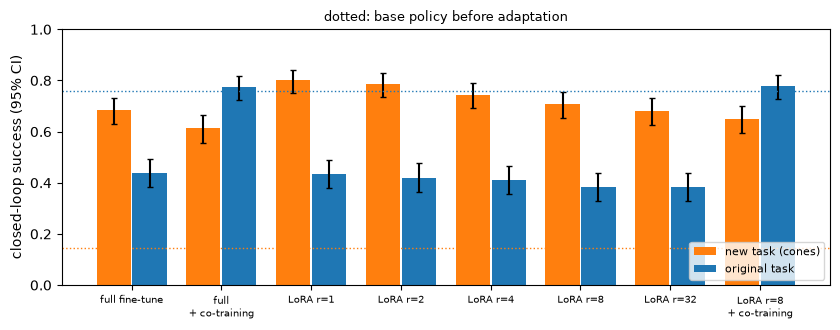

In [11]:
fig, ax = plt.subplots(figsize=(8.5, 3.4))
x = np.arange(len(rows))
for off, key, col in [(-0.2, "cones", "C1"), (0.2, "original", "C0")]:
    vals = np.array([r_[key].mean() for r_ in rows])
    ci = np.array([wilson(r_[key].sum(), len(r_[key])) for r_ in rows])
    ax.bar(x + off, vals, 0.38, color=col, label={"cones": "new task (cones)", "original": "original task"}[key],
           yerr=[vals - ci[:, 0], ci[:, 1] - vals], capsize=2)
ax.axhline(base_scores["original"].mean(), color="C0", ls=":", lw=1)
ax.axhline(base_scores["cones"].mean(), color="C1", ls=":", lw=1)
ax.set_xticks(x, [r_["method"].replace(" + ", "\n+ ") for r_ in rows], fontsize=7.5, rotation=0)
ax.set_ylabel("closed-loop success (95% CI)"); ax.set_ylim(0, 1); ax.legend(fontsize=8, loc="lower right")
ax.set_title("dotted: base policy before adaptation", fontsize=9)
plt.tight_layout(); plt.show()

## 4. Paired comparisons
All methods were evaluated on the *same* 300 episodes (same seeds), so two methods can be compared episode by
episode. Only the **discordant** episodes — solved by one and not the other — carry information about which is
better (McNemar's test): with $b$ and $c$ discordant counts, $z=(b-c)/\sqrt{b+c}$.

In [12]:
def paired(a, b, name_a, name_b, key):
    sa, sb = a[key], b[key]
    b_, c_ = int((sa & ~sb).sum()), int((~sa & sb).sum())
    z = (b_ - c_) / math.sqrt(b_ + c_) if b_ + c_ else 0.0
    print(f"{key:8s} {name_a} vs {name_b}: {b_} episodes only the first solves, {c_} only the second; z = {z:+.1f}")


by = {r_["method"]: r_ for r_ in rows}
paired(by["full fine-tune"], by["full + co-training"], "full FT", "full FT + co-training", "original")
paired(by["full fine-tune"], by["LoRA r=8"], "full FT", "LoRA r=8", "cones")
paired(by["LoRA r=1"], by["LoRA r=32"], "LoRA r=1", "LoRA r=32", "cones")

original full FT vs full FT + co-training: 10 episodes only the first solves, 111 only the second; z = -9.2
cones    full FT vs LoRA r=8: 23 episodes only the first solves, 30 only the second; z = -1.0
cones    LoRA r=1 vs LoRA r=32: 52 episodes only the first solves, 16 only the second; z = +4.4


**Reading the results** (compare with book 9.1 and 9.4). In the committed run, fine-tuning on cones alone teaches
cones (0.15 → 0.68) but erodes the original task (0.76 → 0.44). Co-training keeps the original task (0.77) at the
cost of some cone success (0.61); the paired test makes the difference unmistakable. LoRA trains 0.6–18% of the
parameters, and its *smallest* ranks learn cones best (rank 1: 0.80, significantly better than rank 32) — yet it
forgets the original task just as much as full fine-tuning (≈0.40). Fewer trainable parameters did not protect the
old task; keeping old data in the batches did. Check these statements against your own intervals and paired tests,
not against the bar heights.

## Exercises
1. **Codec settings.** Re-encode with `crf` 10 and 35, and with `pix_fmt="yuv444p"`. Plot pixel error and the
   trained policy's success against file size.
2. **Failed demonstrations.** Train on all episodes including the sloppy ones (`only_success=False`). Is the
   effect visible with 5% sloppy episodes? With 30%?
3. **Normalisation statistics.** Scale the cone task's actions by 0.5 (a slower robot) and adapt with and without
   re-normalising actions with the new `stats.json` (book 8.3). What breaks?
4. **Where to put LoRA.** Apply LoRA only to attention projections, only to the MLPs, or also to the image
   projection. Which matters for a new *object*, which for a new *action space*?
5. **Data efficiency.** Repeat the adaptation with 30, 100 and 1000 episodes; at which size does full
   fine-tuning overtake LoRA?
6. **Use the real library.** If you install `lerobot` (Lab 14), load `data/lerobot/depot_nav` with
   `LeRobotDataset` and check it reads; fix anything your hand-written metadata is missing.
7. **Seeds.** Repeat §2's comparison (recorded vs decoded frames) with three training seeds each. Is the gap larger
   than the spread between seeds?